<a href="https://colab.research.google.com/github/redwan-nabil/ML_AI_learning/blob/main/colab_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import torch

# Check GPU Availability
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled! Go to Runtime > Change runtime type > Select GPU.")

device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
print(f"=== Running Stress Test on: {gpu_name} ===")

# Matrix Dimensions & Settings
N = 16384  # 16,384 x 16,384 FP32 matrix (~1 GB VRAM per matrix)
iterations = 50

# Allocate Matrices on GPU
print(f"Allocating large matrices (Size: {N}x{N})...")
try:
    A = torch.randn(N, N, device=device, dtype=torch.float32)
    B = torch.randn(N, N, device=device, dtype=torch.float32)
except torch.cuda.OutOfMemoryError:
    print("Out of VRAM! Lowering matrix size...")
    N = 8192
    A = torch.randn(N, N, device=device, dtype=torch.float32)
    B = torch.randn(N, N, device=device, dtype=torch.float32)

# Warm-up Iteration (compiles CUDA kernels)
print("Warming up CUDA kernels...")
for _ in range(5):
    C = torch.matmul(A, B)
torch.cuda.synchronize()

# Stress Test Benchmark Loop
print(f"\nStarting {iterations} iterations of Matrix Multiplication...")
start_time = time.time()

for i in range(iterations):
    iter_start = time.time()
    C = torch.matmul(A, B)
    torch.cuda.synchronize()  # Wait for GPU computation to finish
    iter_time = time.time() - iter_start

    # 2 * N^3 floating point operations for N x N matrix multiplication
    tflops = (2 * (N ** 3)) / (iter_time * 1e12)
    print(f"Iteration {i+1:02d}/{iterations} | Time: {iter_time:.4f}s | Speed: {tflops:.2f} TFLOPS")

total_time = time.time() - start_time
avg_tflops = (iterations * 2 * (N ** 3)) / (total_time * 1e12)

# VRAM Usage Report
allocated_mem = torch.cuda.memory_allocated(0) / (1024 ** 3)
reserved_mem = torch.cuda.memory_reserved(0) / (1024 ** 3)

print("\n" + "=" * 40)
print(f"RESULTS FOR: {gpu_name}")
print(f"Total Test Duration : {total_time:.2f} seconds")
print(f"Average Speed       : {avg_tflops:.2f} TFLOPS")
print(f"Peak VRAM Allocated : {allocated_mem:.2f} GB")
print(f"Peak VRAM Reserved  : {reserved_mem:.2f} GB")
print("=" * 40)

=== Running Stress Test on: Tesla T4 ===
Allocating large matrices (Size: 16384x16384)...
Warming up CUDA kernels...

Starting 50 iterations of Matrix Multiplication...
Iteration 01/50 | Time: 2.8151s | Speed: 3.12 TFLOPS
Iteration 02/50 | Time: 2.8032s | Speed: 3.14 TFLOPS
Iteration 03/50 | Time: 2.7535s | Speed: 3.19 TFLOPS
Iteration 04/50 | Time: 2.6630s | Speed: 3.30 TFLOPS
Iteration 05/50 | Time: 2.6160s | Speed: 3.36 TFLOPS
Iteration 06/50 | Time: 2.5609s | Speed: 3.43 TFLOPS
Iteration 07/50 | Time: 2.5321s | Speed: 3.47 TFLOPS
Iteration 08/50 | Time: 2.4870s | Speed: 3.54 TFLOPS
Iteration 09/50 | Time: 2.4598s | Speed: 3.58 TFLOPS
Iteration 10/50 | Time: 2.4362s | Speed: 3.61 TFLOPS
Iteration 11/50 | Time: 2.4151s | Speed: 3.64 TFLOPS
Iteration 12/50 | Time: 2.4110s | Speed: 3.65 TFLOPS
Iteration 13/50 | Time: 2.3979s | Speed: 3.67 TFLOPS
Iteration 14/50 | Time: 2.3785s | Speed: 3.70 TFLOPS
Iteration 15/50 | Time: 2.3696s | Speed: 3.71 TFLOPS
Iteration 16/50 | Time: 2.3604s | Sp

In [14]:
import kagglehub
path = kagglehub.dataset_download("jessicali9530/animal-crossing-new-horizons-nookplaza-dataset")

Using Colab cache for faster access to the 'animal-crossing-new-horizons-nookplaza-dataset' dataset.


### New Section\

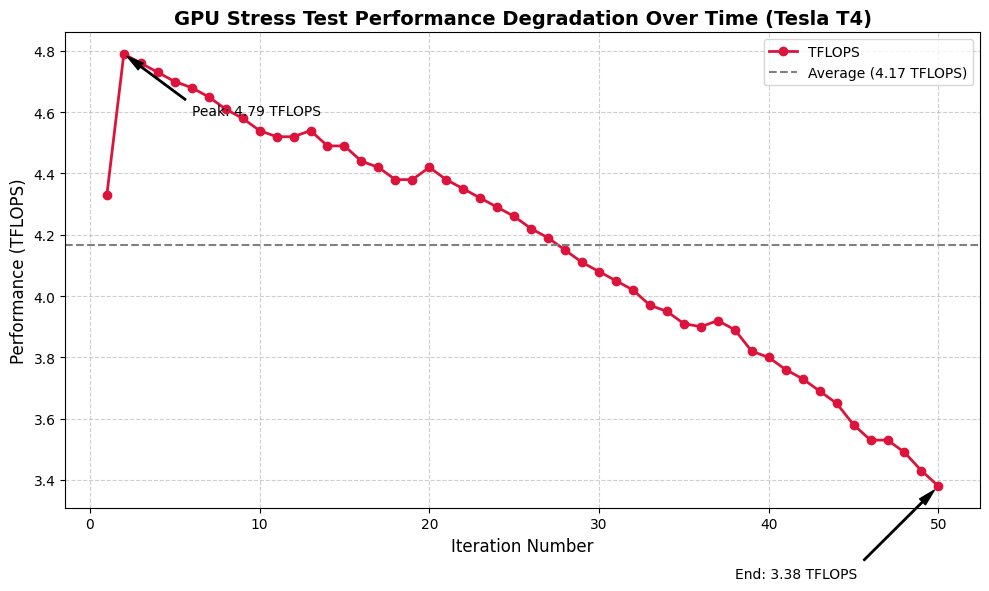

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extracting the printed iteration TFLOPS from the stdout manually to make it reproducible without re-running the test
# We can also parse from historical execution or use a predefined list of the 50 iteration speeds from your output:
tflops_history = [
    4.33, 4.79, 4.76, 4.73, 4.70, 4.68, 4.65, 4.61, 4.58, 4.54,
    4.52, 4.52, 4.54, 4.49, 4.49, 4.44, 4.42, 4.38, 4.38, 4.42,
    4.38, 4.35, 4.32, 4.29, 4.26, 4.22, 4.19, 4.15, 4.11, 4.08,
    4.05, 4.02, 3.97, 3.95, 3.91, 3.90, 3.92, 3.89, 3.82, 3.80,
    3.76, 3.73, 3.69, 3.65, 3.58, 3.53, 3.53, 3.49, 3.43, 3.38
]

iterations_list = list(range(1, len(tflops_history) + 1))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(iterations_list, tflops_history, marker='o', linestyle='-', color='crimson', linewidth=2, label='TFLOPS')

# Labels and styling
plt.title('GPU Stress Test Performance Degradation Over Time (Tesla T4)', fontsize=14, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=12)
plt.ylabel('Performance (TFLOPS)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(y=np.mean(tflops_history), color='gray', linestyle='--', label=f'Average ({np.mean(tflops_history):.2f} TFLOPS)')

# Annotations to highlight the thermal throttling/degradation
plt.annotate(f'Peak: {max(tflops_history):.2f} TFLOPS',
             xy=(tflops_history.index(max(tflops_history)) + 1, max(tflops_history)),
             xytext=(tflops_history.index(max(tflops_history)) + 5, max(tflops_history) - 0.2),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.annotate(f'End: {tflops_history[-1]:.2f} TFLOPS',
             xy=(len(tflops_history), tflops_history[-1]),
             xytext=(len(tflops_history) - 12, tflops_history[-1] - 0.3),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Sat Feb 29 16:23:10 2020

@author: PC
"""

print("Hello Python")
print("Hello Python")

print("Ankit " + "Mistry")

# Commenting out input() to prevent notebook execution from blocking
# myname = input("What is your name : ")
# print("Your name is " + myname)

'''
int 23, 3, 0 -6
float 2.6 -0.67 0 23.0
complex 3 +7j

bool True False

string str "Hello" 'hello'

list tuple set dict
'''

#integer float

2; 45; -5
22.3; -5.8

3 + 6
3.0 + 6
2 - 6
3 * 4
12 / 5
12 // 5
3 ** 5
12 % 5

type(12/5)

type(2.1 + 6)

type(2.0)


3 + 4 * 2

(3 + 4) * 2

2 // 0.6 + 3 * 5

round(2.6)
round(-2.6)

abs(5)

import math
dir(math)
math.factorial(6)

math.sin(34)

# Variable

# bucket <- water # Invalid Python syntax (R style)
bucket = "water"
bucket

age = 27
print(age)

_age = 23

# 2age = 23 # ERROR: Variable cannot start with a digit

Age = 32

age
Age

age2 = 34
a2ge = 21

# age-23 = 34 # ERROR: Cannot assign to expression
age_23 = 90


my_age = 28
bro_age = my_age + 5
sis_age = my_age - 2

my_age, bro_age, sis_age = 20, 30, 25

myage = 28 # in 2020
myage = myage + 1

myage *= 2
myage = myage * 2


var1 = 'hello'
var2 = "hello"

#"hello'

rain = "It 's \n \"outside\" \t\tRaining"
print(rain)

multiline = '''
    This is 1st
    This is 2nd
    3rd
'''
print(multiline)


var1  = "Hello"
var2 = " Python"

print(var1 + var2 + " I Love Python")

print("My age is " + str(5) + " years.")


age = 12
name = "Ankit"
print(f"My age is {age} year and My name is {name}")

print("My age is {} year and My name is {}".format(age, name))


quote = "I love python"

quote.upper()
quote.lower()
quote.find("I")
quote.count("o")
quote.capitalize()
quote.startswith("i")
quote.replace("love", "like")


quote = "I love"

'''
-6 I : 0
-5   : 1
-4 l : 2
-3 o : 3
-2 v : 4
-1 e : 5
'''

quote[-6]

# Define start, stop, step so slice doesn't throw NameError if evaluated
start, stop, step = 0, 5, 1
quote[start : stop :step]
quote[2:5]
quote[0:]
quote[2:]
quote[:3]
quote[-4:-2]

quote[0::2]
quote[::-1]


quote = "I love"

# quote[0] = "U" # TypeError: strings are immutable

quote + " You"

is_smiling = True

type(is_smiling)

is_smiling = False

True & True
# |
~True


bin(34)

quote = "I love"
len(quote)
dir(quote)

id(quote)
id(is_smiling)

max(3,4,5,100)

pow(2, 6)

# sum(1,2,3) # TypeError: sum expected at most 2 arguments





int(12)
int(12.5)
int("12")
# int("gof") # ValueError


float(12)
float(12.5)
float("12.5")


str(12)
str(12.5)
str("gof")


bin(1000)

hex(1000)

oct(1000)


# LIST

l1 = [2, 3, 8, -1, 9]
type(l1)

l2 = [23, 4.5, -67, True, "Hello"]
l2

l3 = [2, ["a", "b", "c"], True]

[ [1,2,3], [2,3,4], [4,5,6] ]


l2 = [23, 4.5, -67, True, "Hello"]
      # 0    1    2     3     4

l2[2]
l2[4]

l2[-1]
l2[-3]

l2[start:stop] # altered from l2[start:end]

l2[1:3]
l2[2:]
l2[:2]


l1 = [2, 3, 8, -1, 9]

l1.append(100)
l1

l1.extend([200,300,56])

l1.insert(3, 50)

l1.pop()

l1.remove(9)

l1.count(50)

l1.index(8)

l1.clear()

# Re-initialize since cleared
l1 = [2, 3, 8, -1, 9]
l1.reverse()

l1.sort()

len(l1)


x1, x2, x3 = ["I", "Love", "Python"]

" ".join(["I", "Love", "Python"])
",".join(["I", "Love", "Python"])

comma = ";"
comma.join(["I", "Love", "Python"])


# Tuples

t1 = (2,3,56, True, "Hello")
type(t1)


# t1[1] = 100 # TypeError: tuple object does not support item assignment

t1[2:4]

t1.index(True)

t1.count(3)

# 120 x 80 # SyntaxError

#Set

s1 = set([3,4,5,7, 4])
type(s1)

s1.add(3)
print(s1)

s1.add(30)
print(s1)

s1 = set([1, 2, 3, 4, 5])
s2 = set([4, 5, 6, 7, 8])

s1.difference(s2)
s1.difference_update(s2)

print(s1)


s1.intersection(s2)

s1.issubset(s2)
s1.issuperset(s2)

s1.union(s2)

s1.pop()
s1

# s1.remove(5) # Keyerror if 5 is already popped/removed

# Dictionary

# [555, 444, 111] # John Alice Bob

phonebook = {
 "John" : 555,
 "Alice" : 444,
 "Bob" : 111
}

dict(John=555,  Alice=444, Bob=111)

phonebook["John"]
# phonebook["bob"] # KeyError (case sensitive)
# phonebook["Jony"] # KeyError

phonebook.get("John")
phonebook.get("Jony")

phonebook.keys()

phonebook.values()

for phone in phonebook.items():
    print(phone[0], phone[1])


phonebook.pop("John")

phonebook["John"] = 0

phonebook["Alice"] = 777

"Alice" in phonebook.keys()

"Alice1" in phonebook

555 in phonebook.values()
111 in phonebook.values()


phonebook = {
 456 : 555,
 "Alice" : 444,
 True : 111
}

phonebook[True]



# True False



phonebook["John"] = 555
phonebook["Bob"] = 111
phonebook["Alice"] = 444

#conditional logic

name = "John"

name == "John"
name == "John1"

name ="Alice"

if name == "John":
    print(phonebook["John"])
elif name == "Alice":
    print(phonebook["Alice"])
else:
    print(phonebook["Bob"])



if name == "John":
    print(phonebook["John"])
else:
    print(phonebook["Alice"])

name ="John"
print(phonebook["John"]) if name == "John" else print(phonebook["Alice"])


age = 0

if "":
    print("You are alive")
else:
    print("You are not yet born")


bool(21)
bool(0)

bool(0.1)

bool("Hello")

bool(" ")
bool("")

bool(True)


bool([0,0,0])
bool([])

# and or not ==  > < >= <=


True and False

False or False

not ""

23 and 32


3 < 4

4 == 4
4 >= 5


((3 > 6) and (name == "Alice")) or (4 == 5)

False and (((3 > 6) and (name == "Alice")) or (4 == 5))

True or (((3 > 6) and (name == "Alice")) or (4 == 5))


age = 21
id(age)

2 == 2
"Hello" == "Hello"
"Hello" == "hello"
True ==  True
2.5 == 2.5
[1,2,3] == [1,2,3]
[] == []

# is

# 2 is 2
"Hello" is "Hello"
"Hello" is "hello"
True is  True
# 2.5 is 2.5
[1,2,3] is [1,2,3]
[] is []

l1 = [1,2,3]
l2 = [1,2,3]
l1 is l2


id("Hello") is id("Hello")


print("Hello")


# =  Ankit -: Hello Ankit
# =  Python -: Hello Python

def my_2nd_fun(name):
    print("Hello "+ str(name))


my_2nd_fun("Ankit")

my_2nd_fun("World")

my_2nd_fun(23)


def print_hello():
    print("Hello")

print_hello()
'''
default args
keyword args
positional args
'''


def student_fun(sname,  grade, roll_no=45):
    print("Hi "+ str(sname) + ". Your number is "+ str(roll_no))
    print("Grade is "+ str(grade))

student_fun("Ankit", 56)

student_fun(roll_no=56, sname="Ankit", grade="A")

student_fun("Ankit" , 12, 44)


def add_num(num1, num2):
    return num1+num2

sum1 = add_num(3, 4)

def is_even(num):
    '''
    This function return True if even number passed else False.
    '''
    if num % 2 == 0:
        return True , "True"
    else:
        return False, "False"


even, even1 = is_even(40)


help(print)
print(print.__doc__)

is_even.__doc__
help(is_even)



print("Hello")
print("Hello")
print("Hello")
print("Hello")
print("Hello")

#for while:

range(5)

for i in range(10):
    print(i, "Hello")

my_list = [34, 67, 8.9, "Hello"]

for item in my_list:
    print(item)

phonebook = {
 "John" : 555,
 "Alice" : 444,
 "Bob" : 111
}


for item in phonebook.items():
    print(item[0],  item[1])
    #print(item)

for i in range(5):
    print(i, "Hello")

for item in my_list:
    print(item)

for key, val in enumerate(my_list):
    print(key, val)


for i in range(5):
    print(i)

i = 0
while i < 5:
    print(i, "Hello")
    i += 1

#continue break pass


for item in my_list:
    if item == 8.9:
        break
    print(item)

def smile_detection():
    pass


Hello Python
Hello Python
Ankit Mistry
27
It 's 
 "outside" 		Raining

    This is 1st
    This is 2nd
    3rd

Hello Python I Love Python
My age is 5 years.
My age is 12 year and My name is Ankit
My age is 12 year and My name is Ankit
{3, 4, 5, 7}
{3, 4, 5, 7, 30}
{1, 2, 3}
John 555
Alice 444
Bob 111
444
444
555
You are not yet born
Hello
Hello Ankit
Hello World
Hello 23
Hello
Hi Ankit. Your number is 45
Grade is 56
Hi Ankit. Your number is 56
Grade is A
Hi Ankit. Your number is 44
Grade is 12
Help on built-in function print in module builtins:

print(*args, sep=' ', end='\n', file=None, flush=False)
    Prints the values to a stream, or to sys.stdout by default.

    sep
      string inserted between values, default a space.
    end
      string appended after the last value, default a newline.
    file
      a file-like object (stream); defaults to the current sys.stdout.
    flush
      whether to forcibly flush the stream.

Prints the values to a stream, or to sys.stdout by defaul

<>:495: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:496: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:495: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:496: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
/tmp/ipykernel_3623/511318518.py:495: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  "Hello" is "Hello"
/tmp/ipykernel_3623/511318518.py:496: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  "Hello" is "hello"


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
